## Data Wrangling & EDA

This notebook performs EDA on a single dataset.

- Load a dataset (any one dataset)
- Visualize distributions (histograms, boxplots, correlations)
- Find missing values
- Find outliers and other typical EDA checks



### 1) Load dataset & basic schema checks

- Read `twitter_training.csv` (UTF-8)
- Inspect shape, columns, and dtypes
- Preview a few rows


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')

# Load dataset
DATA_PATH = 'twitter_training.csv'
df = pd.read_csv(DATA_PATH, encoding='utf-8')

print('Shape:', df.shape)
df.head()


Shape: (74681, 4)


,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


In [21]:
# Basic schema info
print('\nColumn dtypes:')
print(df.dtypes)

print('\nSummary (numeric):')
display(df.describe())

print('\nSummary (including categorical/text):')
display(df.describe(include='all'))



Column dtypes:
2401                                                      int64
Borderlands                                              object
Positive                                                 object
im getting on borderlands and i will murder you all ,    object
dtype: object

Summary (numeric):


,2401
count,74681.000000
mean,6432.640149
std,3740.423819
min,1.000000
25%,3195.000000
50%,6422.000000
75%,9601.000000
max,13200.000000



Summary (including categorical/text):


,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
count,74681.000000,74681,74681,73995
unique,NaN,32,4,69490
top,NaN,Microsoft,Negative,"At the same time, despite the fact that there ..."
freq,NaN,2400,22542,172
mean,6432.640149,NaN,NaN,NaN
std,3740.423819,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,3195.000000,NaN,NaN,NaN
50%,6422.000000,NaN,NaN,NaN
75%,9601.000000,NaN,NaN,NaN


### Normalize placeholders to NaN (text/categorical)

- Strip whitespace in text columns
- Convert common placeholders ("", "N/A", "NA", "None", "Null", "-", "--") to NaN
- Preserve original NaN values


In [22]:
# Normalize placeholders to NaN for object/text columns
placeholders = {"", " ", "N/A", "NA", "None", "NULL", "Null", "null", "-", "--"}
obj_cols = df.select_dtypes(include=['object']).columns

for col in obj_cols:
    # Strip whitespace
    df[col] = df[col].astype(str).str.strip()
    # Replace placeholders with actual NaN
    df[col] = df[col].replace(list(placeholders), np.nan)

print('Normalized placeholders to NaN in object/text columns.')


Normalized placeholders to NaN in object/text columns.


### 2) Visualize distributions (histograms & boxplots)

- Numeric: histograms and boxplots per feature
- Categorical: top-N bar charts (if present)
- Text: length distributions (if present)


Numeric columns: ['2401']
Object/Text columns: ['Borderlands', 'Positive', 'im getting on borderlands and i will murder you all ,']


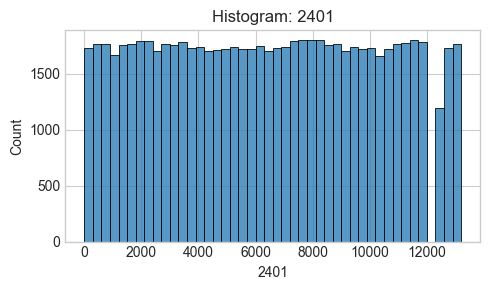

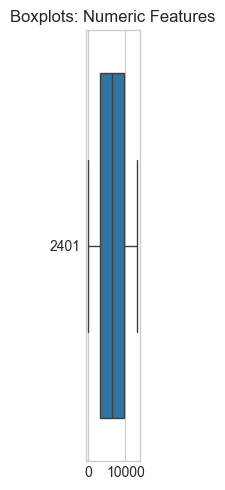

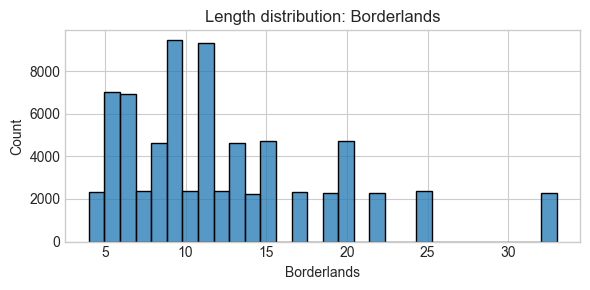

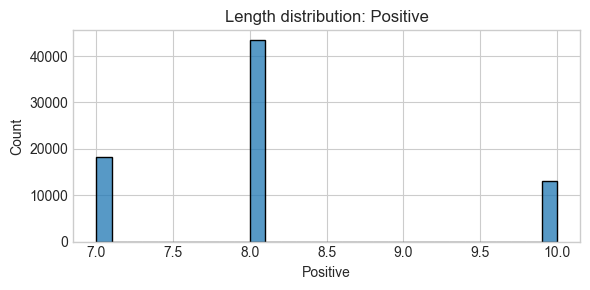

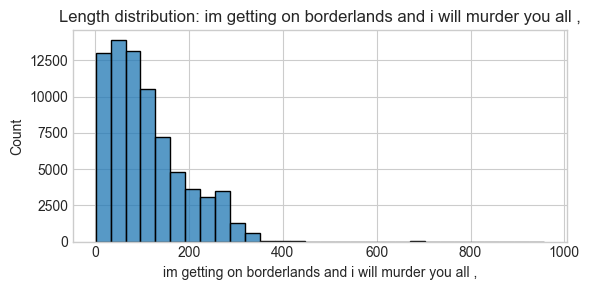

In [23]:
# Identify column types
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
object_cols = df.select_dtypes(include=['object']).columns.tolist()

print('Numeric columns:', numeric_cols)
print('Object/Text columns:', object_cols)

# Histograms for numeric columns
n = len(numeric_cols)
if n:
    ncols = min(3, max(1, n))
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*3))
    # Ensure axes is a flat list of Axes objects
    if isinstance(axes, np.ndarray):
        axes_list = list(np.ravel(axes))
    else:
        axes_list = [axes]

    for i, col in enumerate(numeric_cols):
        ax = axes_list[i]
        sns.histplot(df[col].dropna(), kde=False, ax=ax)
        ax.set_title(f'Histogram: {col}')

    # Turn off any unused axes
    for j in range(n, len(axes_list)):
        axes_list[j].axis('off')

    plt.tight_layout()
    plt.show()

# Boxplots for numeric columns
if n:
    plt.figure(figsize=(min(12, 1.2*len(numeric_cols)), 5))
    sns.boxplot(data=df[numeric_cols], orient='h')
    plt.title('Boxplots: Numeric Features')
    plt.tight_layout()
    plt.show()

# Text length distributions (if any text)
if object_cols:
    for col in object_cols[:3]:  # limit preview to 3 text-like columns
        lengths = df[col].astype(str).str.len()
        plt.figure(figsize=(6,3))
        sns.histplot(lengths, bins=30)
        plt.title(f'Length distribution: {col}')
        plt.tight_layout()
        plt.show()


### 3) Correlations (numeric features)

- Compute Pearson and Spearman correlation matrices
- Visualize heatmap
- Flag highly correlated pairs


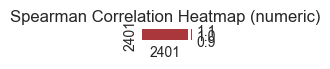

No highly correlated numeric pairs above threshold.


In [24]:
# Correlation matrices and heatmap
if numeric_cols:
    corr_spearman = df[numeric_cols].corr(method='spearman')
    corr_pearson = df[numeric_cols].corr(method='pearson')

    plt.figure(figsize=(min(12, 1.2*len(numeric_cols)), min(10, 0.8*len(numeric_cols))))
    sns.heatmap(corr_spearman, cmap='vlag', center=0, annot=False)
    plt.title('Spearman Correlation Heatmap (numeric)')
    plt.tight_layout()
    plt.show()

    # List highly correlated pairs (abs > 0.85)
    high_pairs = []
    for i, c1 in enumerate(numeric_cols):
        for j, c2 in enumerate(numeric_cols):
            if j <= i: 
                continue
            r = corr_pearson.loc[c1, c2]
            if pd.notna(r) and abs(r) > 0.85:
                high_pairs.append((c1, c2, round(r, 3)))
    if high_pairs:
        print('Highly correlated pairs (pearson |r| > 0.85):')
        for a,b,r in sorted(high_pairs, key=lambda x: -abs(x[2])):
            print(f'- {a} vs {b}: r={r}')
    else:
        print('No highly correlated numeric pairs above threshold.')


### 4) Missing values

- Missing rate per column and per row
- Missingness visualization
- Columns with highest missingness


Missing rate per column (%):


im getting on borderlands and i will murder you all ,    0.23
2401                                                     0.00
Borderlands                                              0.00
Positive                                                 0.00
dtype: float64


Rows with any missing: 172
Rows fully complete: 74509


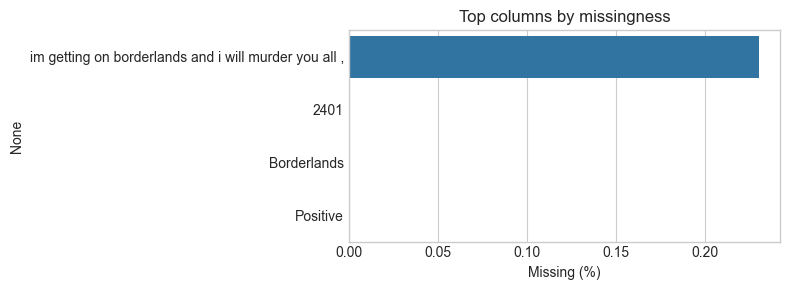

In [25]:
# Missingness summary
missing_per_col = df.isna().mean().sort_values(ascending=False)
print('Missing rate per column (%):')
display((missing_per_col * 100).round(2))

missing_per_row = df.isna().sum(axis=1)
print('\nRows with any missing:', (missing_per_row > 0).sum())
print('Rows fully complete:', (missing_per_row == 0).sum())

# Simple missingness bar plot for top-20 most-missing columns
top_cols = missing_per_col.head(20)
if top_cols.any():
    plt.figure(figsize=(8, max(3, 0.3*len(top_cols))))
    sns.barplot(x=(top_cols * 100), y=top_cols.index, orient='h')
    plt.xlabel('Missing (%)')
    plt.title('Top columns by missingness')
    plt.tight_layout()
    plt.show()


### 5) Outliers and other typical analysis

- Outliers: IQR rule per numeric column; counts and examples
- Typical checks: duplicates, cardinality, constant/near-constant features


In [26]:
# Outlier detection via IQR
outlier_summary = []
for col in numeric_cols:
    s = df[col].dropna()
    if s.empty:
        continue
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = (df[col] < lower) | (df[col] > upper)
    count = mask.sum()
    outlier_summary.append({'column': col, 'iqr': iqr, 'lower': lower, 'upper': upper, 'outlier_count': int(count)})

outlier_df = pd.DataFrame(outlier_summary).sort_values('outlier_count', ascending=False)
display(outlier_df)

# Typical checks
print('\nDuplicate rows:', df.duplicated().sum())

cardinality = df.nunique(dropna=True).sort_values(ascending=False)
print('\nCardinality (unique counts):')
display(cardinality)

# Constant/near-constant (numeric)
near_constant = []
for col in numeric_cols:
    s = df[col]
    nunique = s.nunique(dropna=True)
    if nunique <= 1:
        near_constant.append((col, nunique))

print('\nConstant numeric features:', near_constant if near_constant else 'None')


,column,iqr,lower,upper,outlier_count
0,2401,6406.0,-6414.0,19210.0,0



Duplicate rows: 3067

Cardinality (unique counts):


im getting on borderlands and i will murder you all ,    69141
2401                                                     12447
Borderlands                                                 32
Positive                                                     4
dtype: int64


Constant numeric features: None


### 6) Findings & next steps

- Brief summary of data quality (missingness, duplicates, outliers)
- Notable distribution/correlation patterns
- Optional ideas for imputation/transforms (document only)


In [27]:
# Brief summary of data quality (missingness, duplicates, outliers)
summary = {}

# Shape
summary['rows'] = int(df.shape[0])
summary['columns'] = int(df.shape[1])

# Duplicates
summary['duplicate_rows'] = int(df.duplicated().sum())

# Missingness
missing_counts = df.isna().sum()
missing_cols = (missing_counts > 0).sum()
summary['columns_with_missing'] = int(missing_cols)
summary['total_missing_cells'] = int(missing_counts.sum())
summary['missing_pct_overall'] = round(100 * missing_counts.sum() / (df.shape[0] * df.shape[1]) , 2)

# Top missing columns (up to 5)
top_missing = (missing_counts / len(df)).sort_values(ascending=False).head(5)

# Outliers (IQR) quick summary on numeric columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
outlier_tot = 0
outlier_cols = []
for col in num_cols:
    s = df[col].dropna()
    if s.empty:
        continue
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = (df[col] < lower) | (df[col] > upper)
    cnt = int(mask.sum())
    if cnt > 0:
        outlier_cols.append((col, cnt))
        outlier_tot += cnt

summary['numeric_columns_checked_for_outliers'] = len(num_cols)
summary['total_outlier_flags_IQR'] = int(outlier_tot)

# Display summary
print('Data quality summary:')
for k, v in summary.items():
    print(f'- {k}: {v}')

if missing_cols:
    print('\nTop columns by missingness (%):')
    display((top_missing * 100).round(2).to_frame('missing_%'))

if outlier_cols:
    print('\nColumns with outliers (IQR flagged counts, top 10):')
    display(pd.DataFrame(outlier_cols, columns=['column','iqr_outlier_count']).sort_values('iqr_outlier_count', ascending=False).head(10))
else:
    print('\nNo IQR outliers detected in numeric columns.')


Data quality summary:
- rows: 74681
- columns: 4
- duplicate_rows: 3067
- columns_with_missing: 1
- total_missing_cells: 172
- missing_pct_overall: 0.06
- numeric_columns_checked_for_outliers: 1
- total_outlier_flags_IQR: 0

Top columns by missingness (%):


,missing_%
"im getting on borderlands and i will murder you all ,",0.23
2401,0.00
Borderlands,0.00
Positive,0.00



No IQR outliers detected in numeric columns.
